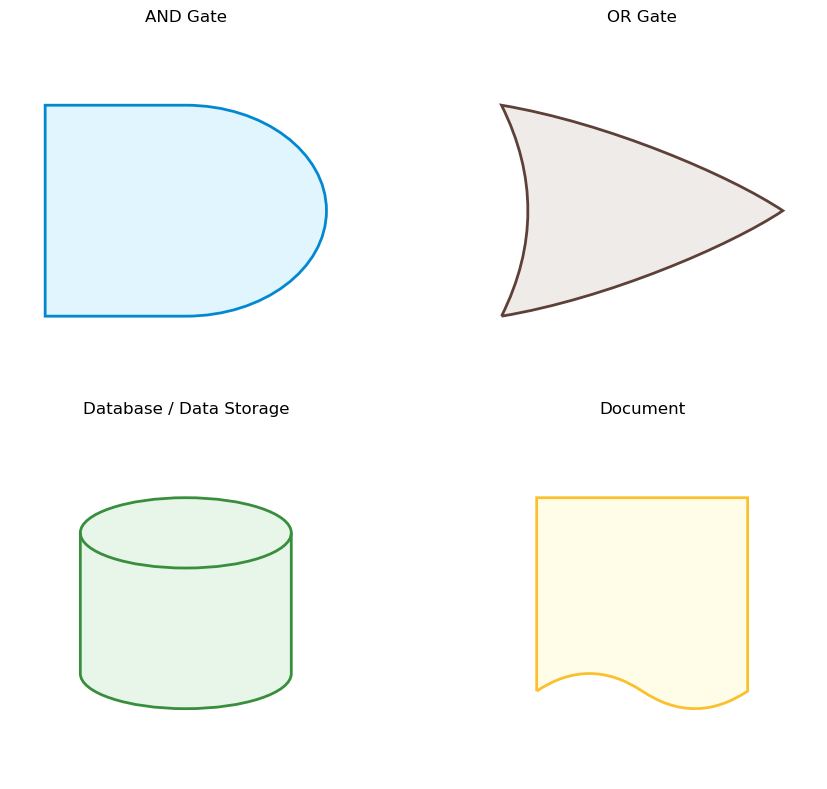

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.path import Path

fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs = axs.ravel()

# Magic constant for drawing near-perfect circular arcs using cubic Bézier curves
KAPPA = 0.552284749831

# =====================================================================
# 1. ACCURATE AND GATE
# =====================================================================
# Straight back, flat top/bottom, and a perfect 180-degree semicircular front
and_verts = [
    (0.1, 0.2),  # Start bottom-left
    (0.1, 0.8),  # Up to top-left
    (0.5, 0.8),  # Right to start of top arc
    # Top half of semicircle arc:
    (0.5 + KAPPA * 0.4, 0.8),
    (0.9, 0.5 + KAPPA * 0.3),
    (0.9, 0.5),
    # Bottom half of semicircle arc:
    (0.9, 0.5 - KAPPA * 0.3),
    (0.5 + KAPPA * 0.4, 0.2),
    (0.5, 0.2),
    (0.1, 0.2),  # Close
]
and_codes = [
    Path.MOVETO,
    Path.LINETO,
    Path.LINETO,
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,  # First cubic Bézier arc
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,  # Second cubic Bézier arc
    Path.CLOSEPOLY,
]

axs[0].add_patch(
    patches.PathPatch(
        Path(and_verts, and_codes), facecolor="#e1f5fe", edgecolor="#0288d1", lw=2
    )
)
axs[0].set_title("AND Gate", fontsize=12, pad=10)

# =====================================================================
# 2. ACCURATE OR GATE
# =====================================================================
# Inward-curved back, swept outer edges meeting at a sharp point
or_verts = [
    (0.1, 0.2),  # Bottom-left
    (0.25, 0.5),
    (0.1, 0.8),  # Inward curved back to top-left
    (0.4, 0.75),
    (0.75, 0.6),
    (0.9, 0.5),  # Swept top edge to sharp apex
    (0.75, 0.4),
    (0.4, 0.25),
    (0.1, 0.2),  # Swept bottom edge back to start
]
or_codes = [
    Path.MOVETO,
    Path.CURVE3,
    Path.CURVE3,  # Curved back
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,  # Upper swept wing
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,  # Lower swept wing
]

axs[1].add_patch(
    patches.PathPatch(
        Path(or_verts, or_codes), facecolor="#efebe9", edgecolor="#5d4037", lw=2
    )
)
axs[1].set_title("OR Gate", fontsize=12, pad=10)

# =====================================================================
# 3. ACCURATE DATABASE (CYLINDER)
# ====================================================================
# Cylinder dimensions
x_center = 0.5
y_top = 0.7
y_bottom = 0.3
rx = 0.3  # Horizontal radius
ry = 0.1  # Vertical radius (controls the perspective angle)

db_verts = [
    (x_center - rx, y_bottom),  # 0: Start at bottom-left corner
    (x_center - rx, y_top),  # 1: Straight up to top-left corner
    # --- Top Back Half Ellipse ---
    (x_center - rx, y_top + KAPPA * ry),  # 2
    (x_center - KAPPA * rx, y_top + ry),  # 3
    (x_center, y_top + ry),  # 4
    (x_center + KAPPA * rx, y_top + ry),  # 5
    (x_center + rx, y_top + KAPPA * ry),  # 6
    (x_center + rx, y_top),  # 7: Top-right corner
    (x_center + rx, y_bottom),  # 8: Straight down to bottom-right corner
    # --- Bottom Front Half Ellipse ---
    (x_center + rx, y_bottom - KAPPA * ry),  # 9
    (x_center + KAPPA * rx, y_bottom - ry),  # 10
    (x_center, y_bottom - ry),  # 11
    (x_center - KAPPA * rx, y_bottom - ry),  # 12
    (x_center - rx, y_bottom - KAPPA * ry),  # 13
    (x_center - rx, y_bottom),  # 14: End of the last curve segment
    (x_center - rx, y_bottom),  # 15: Vertex for CLOSEPOLY
]

db_codes = [
    Path.MOVETO,  # 0
    Path.LINETO,  # 1
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,  # 2, 3, 4
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,  # 5, 6, 7
    Path.LINETO,  # 8
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,  # 9, 10, 11
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,  # 12, 13, 14
    Path.CLOSEPOLY,  # 15
]

# Add main body
axs[2].add_patch(
    patches.PathPatch(
        Path(db_verts, db_codes), facecolor="#e8f5e9", edgecolor="#388e3c", lw=2
    )
)

# =====================================================================
# 2. MATCHING TOP LID OVERLAY
# =====================================================================
# Draws the front half of the top ellipse to complete the cylinder rim.
lid_verts = [
    (x_center + rx, y_top),  # Start at top-right
    # --- Top Front Half Ellipse (Right to Left) ---
    (x_center + rx, y_top - KAPPA * ry),  # Control 1
    (x_center + KAPPA * rx, y_top - ry),  # Control 2
    (x_center, y_top - ry),  # Center front apex
    (x_center - KAPPA * rx, y_top - ry),  # Control 1
    (x_center - rx, y_top - KAPPA * ry),  # Control 2
    (x_center - rx, y_top),  # Ends cleanly at top-left
]

lid_codes = [
    Path.MOVETO,
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,
    Path.CURVE4,
]

# Add the lip line
axs[2].add_patch(
    patches.PathPatch(
        Path(lid_verts, lid_codes), fill=False, edgecolor="#388e3c", lw=2
    )
)
axs[2].set_title("Database / Data Storage", fontsize=12, pad=10)

# =====================================================================
# 4. ACCURATE DOCUMENT SYMBOL
# =====================================================================
# Rectangle with a precise sinusoidal/wave-like torn bottom edge
doc_verts = [
    (0.2, 0.25),  # Start bottom-left
    (0.2, 0.8),  # Up to top-left
    (0.8, 0.8),  # Straight across to top-right
    (0.8, 0.25),  # Down to bottom-right
    # Sinusoidal wave curve back to the start:
    (0.65, 0.15),
    (0.5, 0.25),  # First dip/rise
    (0.35, 0.35),
    (0.2, 0.25),  # Second dip/rise back to origin
]
doc_codes = [
    Path.MOVETO,
    Path.LINETO,
    Path.LINETO,
    Path.LINETO,
    Path.CURVE3,
    Path.CURVE3,
    Path.CURVE3,
    Path.CURVE3,
]

axs[3].add_patch(
    patches.PathPatch(
        Path(doc_verts, doc_codes), facecolor="#fffde7", edgecolor="#fbc02d", lw=2
    )
)
axs[3].set_title("Document", fontsize=12, pad=10)

# Formatting grid uniformly
for ax in axs:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()